# Image inspection

Run all cells from top to bottom in this folder. The folder must contain `train.csv`, `test.csv`, and `images/`. The notebook uses pandas, NumPy, Matplotlib, Pillow, and scikit-learn. Running it writes `predictions.csv`.

The submitted model is the reference-score logistic regression in Part C. The three-feature regression earlier in Part C is a baseline, not the submission.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "test:", test.shape)
display(train.head())

train: (168, 10) test: (72, 8)


,image_id,file,batch,line,camera,shift,timestamp_utc,exposure_setting,inspector_label,inspector_type
0,IMG_0004,images/IMG_0004.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T07:45:00Z,NORMAL,1,stain
1,IMG_0005,images/IMG_0005.jpg,BATCH-A,LINE-1,CAM-B,DAY,2026-11-02T08:00:00Z,LOW,0,none
2,IMG_0006,images/IMG_0006.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T08:15:00Z,NORMAL,1,stain
3,IMG_0007,images/IMG_0007.jpg,BATCH-A,LINE-1,CAM-B,NIGHT,2026-11-02T08:30:00Z,LOW,1,stain
4,IMG_0008,images/IMG_0008.jpg,BATCH-A,LINE-2,CAM-B,DAY,2026-11-02T08:45:00Z,NORMAL,0,none


# Part A — Exploratory data analysis

The labeled file has 168 images. `inspector_label` is 0 for a normal image and 1 for a defective image. It records the inspector's judgment. The next cell checks the columns, missing values, and duplicate ids. The tables below use the labeled images only.

In [2]:
cameras = ["CAM-A", "CAM-B"]
exposure_order = ["LOW", "NORMAL", "AUTO"]
batches = ["BATCH-A", "BATCH-B", "BATCH-C", "BATCH-D"]

print("records:", len(train))
print("columns:", list(train.columns))
print()
print("missing values per column:")
print(train.isna().sum())
print()
print("duplicate rows:", int(train.duplicated().sum()))
print("duplicate image_id:", int(train["image_id"].duplicated().sum()))
print("duplicate file:", int(train["file"].duplicated().sum()))


def defect_summary(frame, column, level_order=None):
    summary = (
        frame.groupby(column, as_index=False)
        .agg(
            n_images=("inspector_label", "size"),
            n_defective=("inspector_label", "sum"),
        )
    )
    summary["percent_defective"] = (
        summary["n_defective"] / summary["n_images"] * 100
    ).round(1)
    if level_order is not None:
        order_map = {level: i for i, level in enumerate(level_order)}
        summary = summary.sort_values(column, key=lambda values: values.map(order_map))
    else:
        summary = summary.sort_values(column)
    return summary.reset_index(drop=True)

records: 168
columns: ['image_id', 'file', 'batch', 'line', 'camera', 'shift', 'timestamp_utc', 'exposure_setting', 'inspector_label', 'inspector_type']

missing values per column:
image_id            0
file                0
batch               0
line                0
camera              0
shift               0
timestamp_utc       0
exposure_setting    0
inspector_label     0
inspector_type      0
dtype: int64

duplicate rows: 0
duplicate image_id: 0
duplicate file: 0


## 1. Label distribution

The training table has 168 rows. No column has missing values, and there are no duplicate rows, image ids, or file paths.

In [3]:
label_counts = (
    train["inspector_label"]
    .value_counts()
    .sort_index()
    .rename_axis("inspector_label")
    .reset_index(name="count")
)
label_counts["percent"] = (label_counts["count"] / label_counts["count"].sum() * 100).round(1)
label_counts["meaning"] = label_counts["inspector_label"].map({0: "normal", 1: "defective"})
label_counts = label_counts[["inspector_label", "meaning", "count", "percent"]]

display(label_counts)

,inspector_label,meaning,count,percent
0,0,normal,112,66.7
1,1,defective,56,33.3


The labeled set has 112 normal images (66.7%) and 56 defective images (33.3%). This is the rate among the labeled images, not the rate of the whole production line.

## 2. Cameras

In [4]:
camera_summary = defect_summary(train, "camera", cameras)
display(camera_summary)

,camera,n_images,n_defective,percent_defective
0,CAM-A,95,30,31.6
1,CAM-B,73,26,35.6


CAM-A is 30/95 (31.6%) and CAM-B is 26/73 (35.6%). The gap is about 4 percentage points. With these counts, that is too small to treat as a camera effect.

## 3. Exposure setting

`LOW`, `NORMAL`, and `AUTO` are three recorded settings. `AUTO` is not a brightness level between `LOW` and `NORMAL`.

In [5]:
exposure_summary = defect_summary(train, "exposure_setting", exposure_order)
display(exposure_summary)

,exposure_setting,n_images,n_defective,percent_defective
0,LOW,48,18,37.5
1,NORMAL,40,14,35.0
2,AUTO,80,24,30.0


`LOW` is 18/48 (37.5%), `NORMAL` is 14/40 (35.0%), and `AUTO` is 24/80 (30.0%). All three are close to the overall 33.3%. Exposure, by itself, does not separate the labels.

## 4. Camera and exposure together

The camera rates are close, but the cameras were not used at the same exposures. The CAM-A / `LOW` cell has no images, so its rate is left blank. The bars are image counts. The heatmap shows the defect rate only where images exist.

,camera,exposure_setting,n_images,n_defective,percent_defective
0,CAM-A,LOW,0,0,NaN
1,CAM-A,NORMAL,30,11,36.7
2,CAM-A,AUTO,65,19,29.2
3,CAM-B,LOW,48,18,37.5
4,CAM-B,NORMAL,10,3,30.0
5,CAM-B,AUTO,15,5,33.3


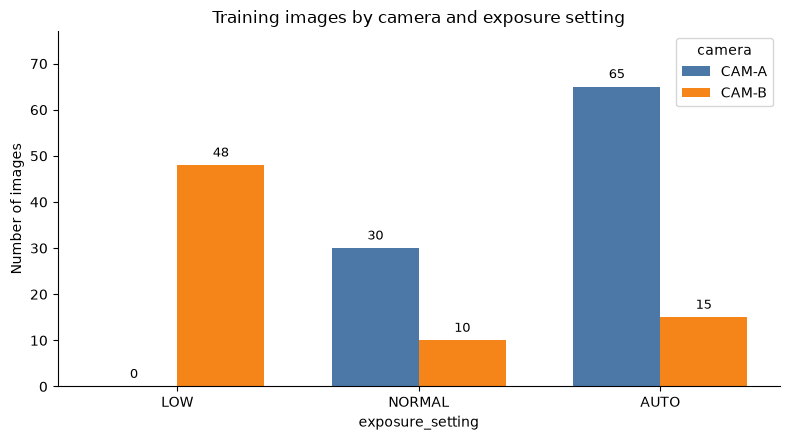

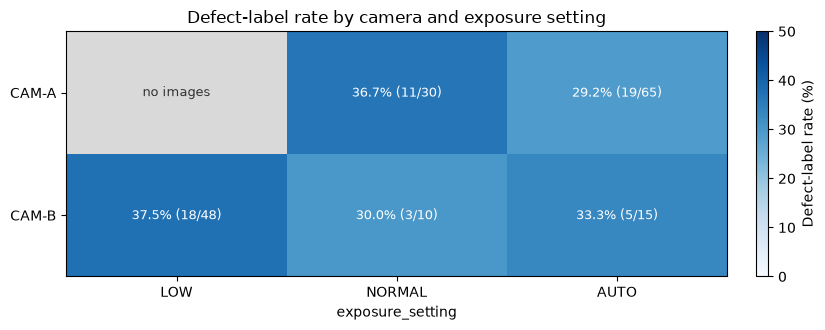

In [6]:
full_index = pd.MultiIndex.from_product(
    [cameras, exposure_order],
    names=["camera", "exposure_setting"],
)
exposure_by_camera = (
    train.groupby(["camera", "exposure_setting"])
    .agg(
        n_images=("inspector_label", "size"),
        n_defective=("inspector_label", "sum"),
    )
    .reindex(full_index, fill_value=0)
    .reset_index()
)
n_images = exposure_by_camera["n_images"].astype(float)
exposure_by_camera["percent_defective"] = (
    exposure_by_camera["n_defective"] / n_images.replace(0, np.nan) * 100
).round(1)
display(exposure_by_camera)

counts = (
    pd.crosstab(train["exposure_setting"], train["camera"])
    .reindex(index=exposure_order, columns=cameras)
    .fillna(0)
    .astype(int)
)

fig_counts, ax_counts = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(exposure_order))
width = 0.36
colors = {"CAM-A": "#4C78A8", "CAM-B": "#F58518"}
for i, camera in enumerate(cameras):
    offset = (i - 0.5) * width
    bars = ax_counts.bar(
        x + offset,
        counts[camera],
        width,
        label=camera,
        color=colors[camera],
    )
    for bar, value in zip(bars, counts[camera]):
        ax_counts.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.2,
            str(int(value)),
            ha="center",
            va="bottom",
            fontsize=9,
        )
ax_counts.set_xticks(x)
ax_counts.set_xticklabels(exposure_order)
ax_counts.set_xlabel("exposure_setting")
ax_counts.set_ylabel("Number of images")
ax_counts.set_title("Training images by camera and exposure setting")
ax_counts.set_ylim(0, counts.values.max() + 12)
ax_counts.legend(title="camera")
ax_counts.spines["top"].set_visible(False)
ax_counts.spines["right"].set_visible(False)
fig_counts.tight_layout()

rate_pct = (
    exposure_by_camera.pivot(index="camera", columns="exposure_setting", values="percent_defective")
    .reindex(index=cameras, columns=exposure_order)
)
n_image_grid = (
    exposure_by_camera.pivot(index="camera", columns="exposure_setting", values="n_images")
    .reindex(index=cameras, columns=exposure_order)
)
n_defect_grid = (
    exposure_by_camera.pivot(index="camera", columns="exposure_setting", values="n_defective")
    .reindex(index=cameras, columns=exposure_order)
)
values = rate_pct.to_numpy(dtype=float)
cmap = plt.cm.Blues.copy()
cmap.set_bad("#d9d9d9")

fig_rates, ax_rates = plt.subplots(figsize=(8.4, 3.4))
image = ax_rates.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=0, vmax=50, aspect="auto")
ax_rates.set_xticks(range(len(exposure_order)))
ax_rates.set_xticklabels(exposure_order)
ax_rates.set_yticks(range(len(cameras)))
ax_rates.set_yticklabels(cameras)
ax_rates.set_xlabel("exposure_setting")
ax_rates.set_title("Defect-label rate by camera and exposure setting")
colorbar = fig_rates.colorbar(image, ax=ax_rates, fraction=0.046, pad=0.04)
colorbar.set_label("Defect-label rate (%)")
for row_i in range(len(cameras)):
    for col_i in range(len(exposure_order)):
        n = int(n_image_grid.iloc[row_i, col_i])
        k = int(n_defect_grid.iloc[row_i, col_i])
        if n == 0:
            label = "no images"
            text_color = "#333333"
        else:
            label = f"{values[row_i, col_i]:.1f}% ({k}/{n})"
            text_color = "white" if values[row_i, col_i] >= 25 else "black"
        ax_rates.text(col_i, row_i, label, ha="center", va="center", color=text_color, fontsize=9)
fig_rates.tight_layout()
plt.show()

All 48 `LOW` images come from CAM-B. CAM-A has 65 `AUTO` images and 30 `NORMAL` images, and no `LOW` images. Where both cameras have images, the rates stay close and several counts are small: `AUTO` is 19/65 and 5/15, and `NORMAL` is 11/30 and 3/10. A camera comparison is therefore also an exposure comparison. These cells describe the labeled sample. They do not show that a camera or an exposure causes a defect.

## 5. Batches

Each batch has 42 images. The two expected-percent columns ask whether a batch's camera mix or exposure mix lines up with its defect rate. Each column multiplies that batch's mix by the overall rate of each camera or exposure in these same 168 images. The columns describe the mix. They do not remove it.

In [7]:
batch_summary = defect_summary(train, "batch", batches)
exposure_rates = train.groupby("exposure_setting")["inspector_label"].mean()
camera_rates = train.groupby("camera")["inspector_label"].mean()


def mix_expected_percent(group, column, rates):
    mix = group[column].value_counts(normalize=True)
    return round(float((mix * rates.reindex(mix.index)).sum() * 100), 1)


expected = pd.DataFrame(
    [
        {
            "batch": batch_name,
            "percent_expected_from_exposure_mix": mix_expected_percent(
                group, "exposure_setting", exposure_rates
            ),
            "percent_expected_from_camera_mix": mix_expected_percent(
                group, "camera", camera_rates
            ),
        }
        for batch_name, group in train.groupby("batch")
    ]
)
batch_summary = batch_summary.merge(expected, on="batch")
display(batch_summary)

camera_counts = (
    pd.crosstab(train["batch"], train["camera"])
    .reindex(index=batches, columns=cameras)
)
exposure_counts = (
    pd.crosstab(train["batch"], train["exposure_setting"])
    .reindex(index=batches, columns=exposure_order)
)
composition = camera_counts.join(exposure_counts)
composition.columns = [f"n_{name}" for name in composition.columns]
display(composition.reset_index())

,batch,n_images,n_defective,percent_defective,percent_expected_from_exposure_mix,percent_expected_from_camera_mix
0,BATCH-A,42,14,33.3,33.2,33.0
1,BATCH-B,42,11,26.2,33.0,32.9
2,BATCH-C,42,18,42.9,33.3,33.3
3,BATCH-D,42,13,31.0,33.8,34.1


,batch,n_CAM-A,n_CAM-B,n_LOW,n_NORMAL,n_AUTO
0,BATCH-A,27,15,10,12,20
1,BATCH-B,28,14,10,10,22
2,BATCH-C,24,18,12,10,20
3,BATCH-D,16,26,16,8,18


The labeled counts are BATCH-A 14/42 (33.3%), BATCH-B 11/42 (26.2%), BATCH-C 18/42 (42.9%), and BATCH-D 13/42 (31.0%). The widest gap is 7 images.

The mixes differ: BATCH-D has the most CAM-B images (26) and the most `LOW` images (16), while BATCH-C has the most defective labels. The exposure-mix calculation puts every batch near 33% (33.2, 33.0, 33.3, and 33.8), and the camera-mix calculation does the same (33.0, 32.9, 33.3, and 34.1). The observed gap remains. With 42 images per batch, this is a description of the labeled sample, not evidence that one batch produced worse parts.

## Part A conclusions

There are 168 labeled images, 112 normal (66.7%) and 56 defective (33.3%), with no missing values and no duplicate image ids. Camera rates are 30/95 (31.6%) and 26/73 (35.6%), and the three exposure rates are also close to 33%. The stable pattern is the mix: every `LOW` image comes from CAM-B.

Batch rates run from 11/42 to 18/42. Accounting for each batch's camera and exposure mix still leaves the batches near 33%, so that mix does not explain the gap. `inspector_type` repeats the inspector's label and is not used as a model feature. A dark or bright image is not, by itself, evidence of a defective part.

# Part B — Image features

Three measurements are taken from each of the 168 labeled images. Test images are not used here, and `inspector_type` is not a feature.

**Mean brightness** is the average grayscale value, from 0 (black) to 255 (white).

**Contrast** is the standard deviation of those grayscale values.

**Maximum local contrast** divides each 300×300 image into 100 blocks of 30×30. It is the largest standard deviation among those blocks.

## 1. Six training images

The same six labeled examples are shown again: two normal plates, and four defective plates with a scratch, an edge notch, a missing hole, or a dark spot.

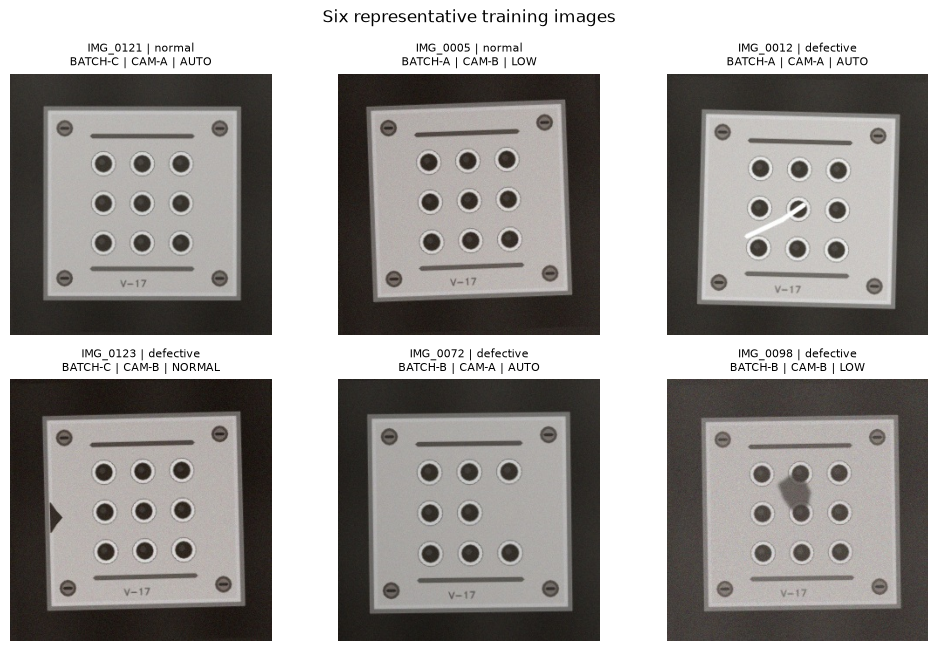

In [8]:
from PIL import Image

example_ids = [
    "IMG_0121",  # normal
    "IMG_0005",  # normal, LOW exposure
    "IMG_0012",  # scratch
    "IMG_0123",  # edge notch
    "IMG_0072",  # missing hole
    "IMG_0098",  # dark spot
]
examples = train.set_index("image_id").loc[example_ids].reset_index()
missing_files = [file_name for file_name in examples["file"] if not (DATA_DIR / file_name).exists()]
if missing_files:
    raise FileNotFoundError(missing_files)

label_name = {0: "normal", 1: "defective"}
fig_examples, example_axes = plt.subplots(2, 3, figsize=(10, 6.6))
for ax, (_, row) in zip(example_axes.ravel(), examples.iterrows()):
    ax.imshow(Image.open(DATA_DIR / row["file"]))
    ax.set_title(
        f"{row['image_id']} | {label_name[row['inspector_label']]}\n"
        f"{row['batch']} | {row['camera']} | {row['exposure_setting']}",
        fontsize=8,
    )
    ax.axis("off")
fig_examples.suptitle("Six representative training images", fontsize=12)
fig_examples.tight_layout()
plt.show()

The plates share the same layout. In this sample the visible differences are local: a thin light line, a notch on an edge, a missing hole, and a dark spot. The two normal images do not show those marks.

## 2. Features for all 168 training images

In [9]:
def image_features(path, block_size=30):
    """Return mean brightness, contrast, and maximum local contrast."""
    gray = np.asarray(Image.open(path).convert("L"), dtype=np.float64)
    mean_brightness = float(gray.mean())
    contrast = float(gray.std())
    height, width = gray.shape
    block_scores = [
        float(gray[y:y + block_size, x:x + block_size].std())
        for y in range(0, height - block_size + 1, block_size)
        for x in range(0, width - block_size + 1, block_size)
    ]
    if len(block_scores) != 100:
        raise ValueError(f"expected 100 blocks, got {len(block_scores)} for {path}")
    max_local_contrast = max(block_scores)
    return mean_brightness, contrast, max_local_contrast


feature_rows = []
for row in train.itertuples(index=False):
    mean_brightness, contrast, max_local_contrast = image_features(DATA_DIR / row.file)
    feature_rows.append(
        {
            "image_id": row.image_id,
            "inspector_label": row.inspector_label,
            "mean_brightness": mean_brightness,
            "contrast": contrast,
            "max_local_contrast": max_local_contrast,
        }
    )
feature_table = pd.DataFrame(feature_rows)

if len(feature_table) != 168:
    raise ValueError(f"expected 168 feature rows, got {len(feature_table)}")
if not feature_table["image_id"].is_unique:
    raise ValueError("duplicate image_id in feature table")
if set(feature_table["image_id"]) != set(train["image_id"]):
    raise ValueError("feature table image ids do not match train.csv")
values = feature_table[["mean_brightness", "contrast", "max_local_contrast"]]
if not np.isfinite(values.to_numpy()).all():
    raise ValueError("feature table contains a non-finite value")
if (
    (values["mean_brightness"] < 0)
    | (values["mean_brightness"] > 255)
    | (values["contrast"] < 0)
    | (values["max_local_contrast"] < 0)
).any():
    raise ValueError("feature table contains a value outside the expected range")

print("feature rows:", len(feature_table))
print("non-finite values:", int((~np.isfinite(values.to_numpy())).sum()))

feature rows: 168
non-finite values: 0


## 3. Normal versus defective

The boxplots and the first table compare the three features by inspector label. The second table groups the same features by the inspector's defect name. That name is a description only. It is not a model input.

,n,median_brightness,iqr_brightness,median_contrast,iqr_contrast,median_local_contrast,iqr_local_contrast
inspector_label,,,,,,,
normal,112,114.3,12.6,66.6,9.0,64.6,9.1
defective,56,111.1,16.3,65.1,11.4,61.8,11.0


,n,median_brightness,median_contrast,median_local_contrast
inspector_type,,,,
none,112,114.3,66.6,64.6
stain,20,109.1,63.7,61.1
edge_chip,14,116.8,64.1,60.4
scratch,13,110.1,64.0,62.3
missing_hole,9,118.9,66.2,63.9


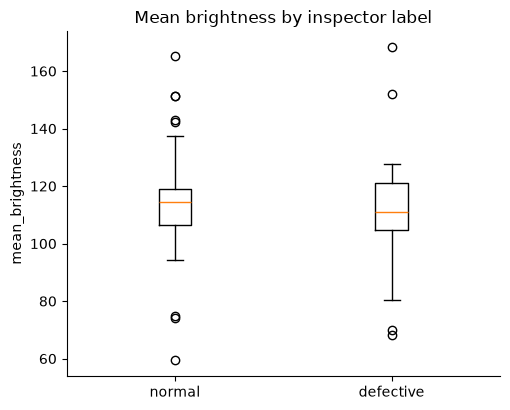

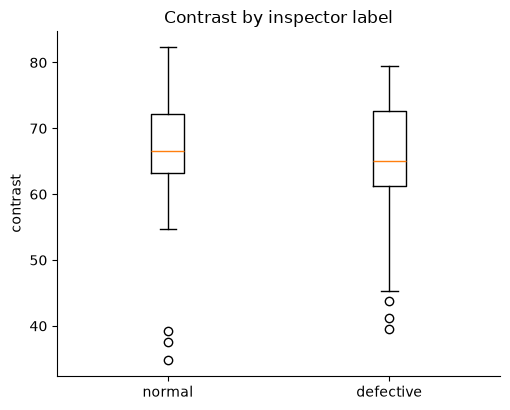

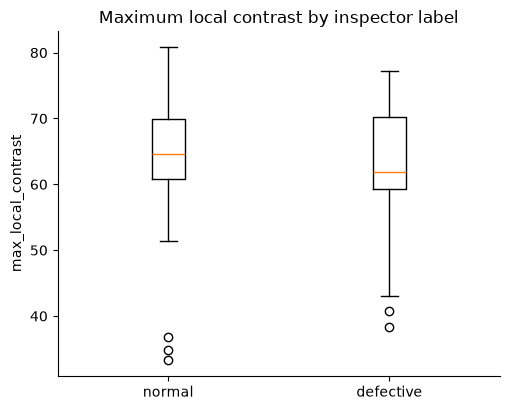

In [10]:
def iqr(values):
    return values.quantile(0.75) - values.quantile(0.25)


comparison = (
    feature_table.groupby("inspector_label")
    .agg(
        n=("image_id", "size"),
        median_brightness=("mean_brightness", "median"),
        iqr_brightness=("mean_brightness", iqr),
        median_contrast=("contrast", "median"),
        iqr_contrast=("contrast", iqr),
        median_local_contrast=("max_local_contrast", "median"),
        iqr_local_contrast=("max_local_contrast", iqr),
    )
)
comparison.loc[:, "median_brightness":] = comparison.loc[:, "median_brightness":].round(1)
comparison.index = comparison.index.map({0: "normal", 1: "defective"})
display(comparison)

typed = feature_table.merge(train[["image_id", "inspector_type"]], on="image_id", how="left")
type_order = ["none", "stain", "edge_chip", "scratch", "missing_hole"]
by_type = (
    typed.groupby("inspector_type")
    .agg(
        n=("image_id", "size"),
        median_brightness=("mean_brightness", "median"),
        median_contrast=("contrast", "median"),
        median_local_contrast=("max_local_contrast", "median"),
    )
    .reindex(type_order)
)
by_type.loc[:, "median_brightness":] = by_type.loc[:, "median_brightness":].round(1)
display(by_type)


def label_boxplot(column, title):
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    groups = [
        feature_table.loc[feature_table["inspector_label"] == label, column]
        for label in (0, 1)
    ]
    ax.boxplot(groups, showfliers=True)
    ax.set_xticks([1, 2], ["normal", "defective"])
    ax.set_ylabel(column)
    ax.set_title(title)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    fig.tight_layout()


label_boxplot("mean_brightness", "Mean brightness by inspector label")
label_boxplot("contrast", "Contrast by inspector label")
label_boxplot("max_local_contrast", "Maximum local contrast by inspector label")
plt.show()

Normal and defective images overlap on all three features. Median brightness is 114.3 for normal images and 111.1 for defective images. Median contrast is 66.6 and 65.1. Median maximum local contrast is 64.6 and 61.8, so the normal group is higher: the holes and the plate border already create strong local contrast.

The defect-name medians, on 9 to 20 images, do not point in one direction. Stain and scratch sit a little below the normal brightness of 114.3, while edge chip and missing hole sit a little above it. A single global measurement therefore has no consistent defect direction.

# Part C — Model

## 1. Baseline

The baseline is a logistic regression on mean brightness, contrast, and maximum local contrast. The 168 labeled images are split 75/25 into development and validation, stratified by `inspector_label`, with `random_state=42`. The scaler and the baseline are fit on the 126 development rows only. The threshold is 0.5, fixed before looking at validation or test results. This baseline is not the submitted model.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feature_columns = ["mean_brightness", "contrast", "max_local_contrast"]
RANDOM_STATE = 42
DECISION_THRESHOLD = 0.5

development, validation = train_test_split(
    feature_table,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=feature_table["inspector_label"],
)
if set(development["image_id"]).intersection(validation["image_id"]):
    raise ValueError("development and validation overlap")
if set(development["image_id"]).union(validation["image_id"]) != set(feature_table["image_id"]):
    raise ValueError("split does not cover every labeled image")

print("development:", len(development), "validation:", len(validation))
print("development labels:")
print(development["inspector_label"].value_counts().sort_index())
print("validation labels:")
print(validation["inspector_label"].value_counts().sort_index())

scaler = StandardScaler()
X_development = scaler.fit_transform(development[feature_columns])
if int(scaler.n_samples_seen_) != len(development):
    raise ValueError("scaler was not fit on the development set only")

model = LogisticRegression(random_state=RANDOM_STATE)
model.fit(X_development, development["inspector_label"])

coefficients = pd.DataFrame(
    {
        "feature": feature_columns,
        "coefficient": model.coef_[0],
    }
)
coefficients["coefficient"] = coefficients["coefficient"].round(3)
display(coefficients)
print("intercept:", round(float(model.intercept_[0]), 3))

development: 126 validation: 42
development labels:
inspector_label
0    84
1    42
Name: count, dtype: int64
validation labels:
inspector_label
0    28
1    14
Name: count, dtype: int64


,feature,coefficient
0,mean_brightness,0.107
1,contrast,-0.212
2,max_local_contrast,-0.043


intercept: -0.702


On the development fit, brightness has weight 0.107, contrast has weight −0.212, and maximum local contrast has weight −0.043. The intercept is −0.702. At the average feature values that is a probability of about 0.33, close to the 42/126 development base rate. The weights are too small to separate the classes. The submitted model is the reference score below.

## 2. Final model

The submitted model is a logistic regression with one input, the Reference Difference Score.

A pixel belongs to the plate when it is more than 40 gray levels above the median of the four 20×20 corners. The crop is resized to 240×240. For each exposure, the reference is the pixel-wise median of the normal development plates at that exposure. The score is the largest mean of the 64 non-overlapping 30×30 blocks in the absolute difference from that reference, after a 5×5 mean filter.

A normal development image is scored against the other normal development images at its exposure, so the fit does not include that image in its own reference. Validation and test images use the reference built from all normal development images at the matching exposure. The threshold remains 0.5. Validation and test images are not used to build the references or to fit the scaler or the model.

In [12]:
from PIL import Image

CORNER_SIZE = 20
PLATE_MARGIN = 40
PLATE_SIZE = 240
BLOCK_SIZE = 30
SMOOTH_SIZE = 5

experiment = development.merge(
    train[["image_id", "file", "exposure_setting"]],
    on="image_id",
    how="left",
)
if len(experiment) != 126:
    raise ValueError(f"expected 126 development images, got {len(experiment)}")
if set(experiment["image_id"]).intersection(validation["image_id"]):
    raise ValueError("experiment includes a validation image")
if experiment[["file", "exposure_setting"]].isna().any().any():
    raise ValueError("a development image did not match train.csv")

normal_experiment = experiment[experiment["inspector_label"] == 0]
normal_counts = normal_experiment["exposure_setting"].value_counts()
if normal_counts.to_dict() != {"AUTO": 41, "LOW": 24, "NORMAL": 19}:
    raise ValueError(f"unexpected normal counts: {normal_counts.to_dict()}")


def plate_box(gray):
    """Return the left, top, width, and height of the bright plate."""
    corners = np.concatenate(
        [
            gray[:CORNER_SIZE, :CORNER_SIZE].ravel(),
            gray[:CORNER_SIZE, -CORNER_SIZE:].ravel(),
            gray[-CORNER_SIZE:, :CORNER_SIZE].ravel(),
            gray[-CORNER_SIZE:, -CORNER_SIZE:].ravel(),
        ]
    )
    mask = gray > (float(np.median(corners)) + PLATE_MARGIN)
    rows = np.flatnonzero(mask.any(axis=1))
    cols = np.flatnonzero(mask.any(axis=0))
    if len(rows) == 0 or len(cols) == 0:
        raise ValueError("plate mask is empty")
    top, bottom = int(rows[0]), int(rows[-1])
    left, right = int(cols[0]), int(cols[-1])
    return left, top, right - left + 1, bottom - top + 1


def prepared_plate(path):
    """Crop the plate and resize it to the common 240 by 240 size."""
    gray = np.asarray(Image.open(path).convert("L"), dtype=np.float64)
    if gray.shape != (300, 300):
        raise ValueError(f"expected 300x300, got {gray.shape} for {path}")
    left, top, width, height = plate_box(gray)
    touches_border = left <= 0 or top <= 0 or left + width >= 300 or top + height >= 300
    crop = gray[top : top + height, left : left + width]
    resized = Image.fromarray(np.clip(np.rint(crop), 0, 255).astype(np.uint8)).resize(
        (PLATE_SIZE, PLATE_SIZE),
        Image.Resampling.BILINEAR,
    )
    plate = np.asarray(resized, dtype=np.float64)
    if plate.shape != (PLATE_SIZE, PLATE_SIZE):
        raise ValueError(f"resized plate has shape {plate.shape} for {path}")
    return plate, left, top, width, height, touches_border



plates = {}
for row in experiment.itertuples(index=False):
    plate, _, _, _, _, touches_border = prepared_plate(DATA_DIR / row.file)
    if touches_border:
        raise ValueError(f"development plate box touches the border: {row.image_id}")
    plates[row.image_id] = plate
if len(plates) != 126:
    raise ValueError("the development plates were not all prepared")

def mean_filter(image, size):
    """Replace every pixel by the mean of its square neighborhood."""
    if size % 2 == 0:
        raise ValueError("filter size must be odd")
    padded = np.pad(image, size // 2, mode="edge")
    windows = np.lib.stride_tricks.sliding_window_view(padded, (size, size))
    return windows.mean(axis=(-1, -2))


def block_means(image):
    """Return the mean of each non-overlapping 30 by 30 block."""
    blocks_per_side = PLATE_SIZE // BLOCK_SIZE
    blocks = image.reshape(blocks_per_side, BLOCK_SIZE, blocks_per_side, BLOCK_SIZE)
    return blocks.mean(axis=(1, 3))


def local_difference_score(plate, reference):
    """Return one score: the strongest smoothed 30 by 30 difference."""
    smoothed = mean_filter(np.abs(plate - reference), SMOOTH_SIZE)
    return float(block_means(smoothed).max())


def median_reference(image_ids):
    if len(image_ids) == 0:
        raise ValueError("a reference would be built from no images")
    return np.median(np.stack([plates[image_id] for image_id in image_ids]), axis=0)


final_reference_ids = {
    exposure: experiment.loc[
        (experiment["inspector_label"] == 0) & (experiment["exposure_setting"] == exposure),
        "image_id",
    ].tolist()
    for exposure in ["AUTO", "LOW", "NORMAL"]
}
if {exposure: len(image_ids) for exposure, image_ids in final_reference_ids.items()} != {
    "AUTO": 41,
    "LOW": 24,
    "NORMAL": 19,
}:
    raise ValueError("the final references are not the normal development images")
if set(experiment["image_id"]).intersection(validation["image_id"]):
    raise ValueError("development and validation overlap")
if set(experiment["image_id"]).union(validation["image_id"]).intersection(test["image_id"]):
    raise ValueError("a test image is in the labeled split")

final_references = {
    exposure: median_reference(image_ids) for exposure, image_ids in final_reference_ids.items()
}
training_scores = []
for row in experiment.itertuples(index=False):
    if row.inspector_label == 0:
        peers = [image_id for image_id in final_reference_ids[row.exposure_setting] if image_id != row.image_id]
        reference = median_reference(peers)
    else:
        reference = final_references[row.exposure_setting]
    training_scores.append(local_difference_score(plates[row.image_id], reference))
training_scores = np.asarray(training_scores, dtype=np.float64).reshape(-1, 1)

final_scaler = StandardScaler()
final_model = LogisticRegression(random_state=42)
final_model.fit(final_scaler.fit_transform(training_scores), experiment["inspector_label"])
if int(final_scaler.n_samples_seen_) != 126:
    raise ValueError("the final scaler was not fit on the 126 development images")
print("reference-score coefficient:", round(float(final_model.coef_[0, 0]), 3))
print("intercept:", round(float(final_model.intercept_[0]), 3))


def reference_probability(path, exposure):
    plate, _, _, _, _, touches_border = prepared_plate(path)
    difference = local_difference_score(plate, final_references[exposure])
    probability = float(final_model.predict_proba(final_scaler.transform([[difference]]))[0, 1])
    brightness_gap = float(plate.mean() - final_references[exposure].mean())
    return probability, difference, brightness_gap, touches_border


test_predictions = []
for row in test.itertuples(index=False):
    probability, difference, brightness_gap, touches_border = reference_probability(
        DATA_DIR / row.file, row.exposure_setting
    )
    test_predictions.append(
        {
            "image_id": row.image_id,
            "predicted_defect": int(probability >= DECISION_THRESHOLD),
            "score": probability,
        }
    )
    if touches_border:
        raise ValueError(f"test plate box touches the border: {row.image_id}")
predictions = pd.DataFrame(test_predictions)
predictions.to_csv(DATA_DIR / "predictions.csv", index=False)

saved = pd.read_csv(DATA_DIR / "predictions.csv")
if list(saved.columns) != ["image_id", "predicted_defect", "score"]:
    raise ValueError(f"unexpected columns: {list(saved.columns)}")
if len(saved) != 72:
    raise ValueError(f"expected 72 predictions, got {len(saved)}")
if not saved["image_id"].is_unique:
    raise ValueError("duplicate image_id in predictions.csv")
if not saved["image_id"].equals(test["image_id"]):
    raise ValueError("prediction ids do not match test.csv in order")
if not saved["predicted_defect"].isin([0, 1]).all():
    raise ValueError("predicted_defect is not 0 or 1")
if not saved["score"].between(0, 1).all():
    raise ValueError("score is outside 0 to 1")
print("predictions:", len(saved))
print(saved["predicted_defect"].value_counts().sort_index().to_string())
print("score min/max:", round(float(saved["score"].min()), 3), round(float(saved["score"].max()), 3))
display(saved.head())


reference-score coefficient: 0.713
intercept: -0.755


predictions: 72
predicted_defect
0    64
1     8
score min/max: 0.157 0.826


,image_id,predicted_defect,score
0,IMG_0001,0,0.208399
1,IMG_0002,0,0.371360
2,IMG_0003,0,0.374610
3,IMG_0010,0,0.200078
4,IMG_0014,0,0.321754


# Part D — Validation

The final model is applied to the 42 validation images. The threshold remains 0.5. These images were not used to build the references or to fit the model, and the results below are not used to change it.

## Confusion matrix, precision, and recall

Confusion matrix
                  predicted normal  predicted defective
actual normal                   23                    5
actual defective                 8                    6

Precision and recall
   threshold  accuracy  precision  recall  TP  FN  FP  TN  roc_auc
0        0.5      0.69      0.545   0.429   6   8   5  23    0.696



defective images identified: 6/14
normal images flagged: 5/28
correlation of absolute brightness gap with score, normal validation images: 0.823
reviewed image: IMG_0220
review reason: misclassified
actual label: 0
predicted defect: 1
score: 0.536
exposure: LOW
reference difference: 53.2
brightness gap: 31.2


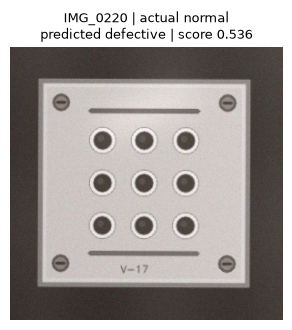

In [13]:
from sklearn.metrics import confusion_matrix, roc_auc_score

validation_final = validation.merge(
    train[["image_id", "file", "exposure_setting"]],
    on="image_id",
    how="left",
)
if len(validation_final) != 42:
    raise ValueError(f"expected 42 validation images, got {len(validation_final)}")
if validation_final["inspector_label"].value_counts().sort_index().to_dict() != {0: 28, 1: 14}:
    raise ValueError("the validation labels are not 28 normal and 14 defective")
if set(validation_final["image_id"]).intersection(experiment["image_id"]):
    raise ValueError("a development image entered the validation check")
if set(validation_final["image_id"]).intersection(test["image_id"]):
    raise ValueError("a test image entered the validation check")

validation_rows = []
for row in validation_final.itertuples(index=False):
    probability, difference, brightness_gap, touches_border = reference_probability(
        DATA_DIR / row.file, row.exposure_setting
    )
    if touches_border:
        raise ValueError(f"validation plate box touches the border: {row.image_id}")
    validation_rows.append(
        {
            "image_id": row.image_id,
            "file": row.file,
            "inspector_label": row.inspector_label,
            "exposure_setting": row.exposure_setting,
            "score": probability,
            "reference_difference": difference,
            "brightness_gap": brightness_gap,
            "predicted_defect": int(probability >= DECISION_THRESHOLD),
        }
    )
validation_eval = pd.DataFrame(validation_rows)
y_true = validation_eval["inspector_label"].to_numpy()
y_pred = validation_eval["predicted_defect"].to_numpy()
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
precision = float("nan") if (tp + fp) == 0 else tp / (tp + fp)
recall = tp / (tp + fn)
accuracy = (tp + tn) / len(validation_eval)
validation_matrix = pd.DataFrame(
    [[int(tn), int(fp)], [int(fn), int(tp)]],
    index=["actual normal", "actual defective"],
    columns=["predicted normal", "predicted defective"],
)
validation_metrics = pd.DataFrame(
    [
        {
            "threshold": DECISION_THRESHOLD,
            "accuracy": round(float(accuracy), 3),
            "precision": round(float(precision), 3) if np.isfinite(precision) else precision,
            "recall": round(float(recall), 3),
            "TP": int(tp),
            "FN": int(fn),
            "FP": int(fp),
            "TN": int(tn),
            "roc_auc": round(float(roc_auc_score(y_true, validation_eval["score"])), 3),
        }
    ]
)
print("Confusion matrix")
print(validation_matrix.to_string())
print()
print("Precision and recall")
print(validation_metrics.to_string())
print()
print("defective images identified:", f"{int(tp)}/14")
print("normal images flagged:", f"{int(fp)}/28")
print(
    "correlation of absolute brightness gap with score, normal validation images:",
    round(
        float(
            validation_eval.loc[validation_eval["inspector_label"] == 0, "brightness_gap"]
            .abs()
            .corr(validation_eval.loc[validation_eval["inspector_label"] == 0, "score"])
        ),
        3,
    ),
)

mistakes = validation_eval[
    validation_eval["predicted_defect"] != validation_eval["inspector_label"]
].copy()
if len(mistakes) == 0:
    candidates = validation_eval.copy()
    review_reason = "uncertain"
else:
    candidates = mistakes
    review_reason = "misclassified"
candidates["distance"] = (candidates["score"] - DECISION_THRESHOLD).abs()
reviewed = candidates.sort_values(["distance", "image_id"]).iloc[0]
print("reviewed image:", reviewed["image_id"])
print("review reason:", review_reason)
print("actual label:", int(reviewed["inspector_label"]))
print("predicted defect:", int(reviewed["predicted_defect"]))
print("score:", round(float(reviewed["score"]), 3))
print("exposure:", reviewed["exposure_setting"])
print("reference difference:", round(float(reviewed["reference_difference"]), 1))
print("brightness gap:", round(float(reviewed["brightness_gap"]), 1))

fig_review, ax = plt.subplots(figsize=(3.4, 3.4))
ax.imshow(Image.open(DATA_DIR / reviewed["file"]))
actual_name = "defective" if reviewed["inspector_label"] == 1 else "normal"
predicted_name = "defective" if reviewed["predicted_defect"] == 1 else "normal"
ax.set_title(
    f"{reviewed['image_id']} | actual {actual_name}\n"
    f"predicted {predicted_name} | score {reviewed['score']:.3f}",
    fontsize=9,
)
ax.axis("off")
fig_review.tight_layout()
plt.show()


## One validation error

IMG_0220 is labeled normal and is predicted defective. Its score is 0.536, so it sits just above the threshold of 0.5. The exposure is LOW. The plate is 31.2 gray levels brighter than the LOW reference, and the reference difference is 53.2. The plate still has the usual holes and corner fasteners, with a bright band along the top. The alert is consistent with that brightness difference. Among the 28 normal validation images, the absolute brightness gap and the model score have correlation 0.823.

# Part E — Conclusions

The labeled images are mostly normal, and the defect rate is similar across cameras, exposures, and batches. The stable pattern is the mix: every LOW image comes from CAM-B, so a camera comparison is also an exposure comparison. Batch differences are only a few images, and they remain after accounting for that mix. I left camera, exposure, and batch out of the model because they describe how the picture was taken, not a mark on the plate. Using them would risk treating a change in lighting or sampling as a change in product quality.

I started with simple image measurements, mean brightness and contrast, and then added maximum local contrast. Normal and defective plates overlap on all three, and the baseline logistic regression gives them only small weights. That weak separation led me to the reference score: crop each plate and compare it with the median normal plate at the same exposure. On the validation set this model detects 6 of 14 defects, with precision 54.5% and recall 42.9%. The main limitation is lighting. A plate that is simply brighter than its reference can cross the threshold even when the part looks normal.

With more labeled images and more time, I would investigate tighter alignment, lighting normalization, data augmentation, and a pretrained image model. Cautious pseudo-labeling of the unlabeled images is another possibility, and only after a human review. These are future options. None of them was implemented or validated here.

AI tools helped me draft and review the code and the written explanations. The numbers in this notebook come from running it. I used the validation set to compare exploratory approaches, while the final model was fit only on the development data; cross-validation within that set supported the same choice, and the threshold stayed at 0.5. The validation set is small, so those comparisons limit how confidently the result generalizes. I did not label the test images by hand, and I did not use them to choose or tune the model.